In [2]:
import os, sys, copy
from collections import OrderedDict

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import xarray as xr
import shap

from PIL import Image
from torchvision import transforms
from omegaconf import OmegaConf

sys.path.append("/home/inhye_yoo/inference_tools/imerg_liif")
from eval_utils import *

sys.path.append("/home/inhye_yoo/deeplearning/inr/liif")
from models.models import make
from datasets.image_folder import TopoInMemory
from utils import make_coord


# ============================================================
# 1. 기본 설정
# ============================================================

device = torch.device("cuda:2" if torch.cuda.is_available() else "cpu")

imerg_path = "/home/inhye_yoo/data/IMERG/Imerg_raw/kor_data/imerg_precip_korea_daily_01deg_1998_2009.nc"
topo_path = "/home/inhye_yoo/data/level/NOAA_ETOPO1_topo/ETOPO1_on_IMERG_Land.nc"

model_config = "/home/inhye_yoo/deeplearning/inr/liif/save/_climate_edsr_imerg_obs_topo_chmeta_final/config.yaml"
ckpt_path = "/home/inhye_yoo/deeplearning/inr/liif/save/_climate_edsr_imerg_obs_topo_chmeta_final/epoch-best.pth"

lat_min, lat_max = 33, 43
lon_min, lon_max = 124, 134

start_date = "1998-01-01"
end_date = "2009-12-31"

H_lr, W_lr = 50, 50
H_hr, W_hr = 100, 100

date = "2009-07-16"   # SHAP 계산할 날짜 하나 선택


# ============================================================
# 2. 유틸 함수
# ============================================================

def make_in_transform(in_mean, in_std):
    return transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize([in_mean], [in_std])
    ])


def ds_slice(xr_ds, date, lat_min, lat_max, lon_min, lon_max):
    var = "precipitation"
    da = xr_ds[var]

    lat_name = "latitude" if "latitude" in da.coords else ("lat" if "lat" in da.coords else None)
    lon_name = "longitude" if "longitude" in da.coords else ("lon" if "lon" in da.coords else None)

    if lat_name is None or lon_name is None:
        raise KeyError(f"lat/lon coord not found. coords={list(da.coords)}")

    sub = da.where(
        (da[lat_name] >= lat_min) & (da[lat_name] <= lat_max) &
        (da[lon_name] >= lon_min) & (da[lon_name] <= lon_max),
        drop=True
    )

    d = pd.Timestamp(date)

    try:
        sub_t = sub.sel(time=d)
    except Exception:
        sub_t = sub.sel(time=d, method="nearest", tolerance=np.timedelta64(1, "D"))

    sub_t = sub_t.sortby(lat_name, ascending=False)

    if tuple(sub_t.dims[-2:]) != (lat_name, lon_name):
        sub_t = sub_t.transpose(..., lat_name, lon_name)

    arr = np.nan_to_num(sub_t.values, nan=0.0).astype(np.float32)

    if arr.size == 0:
        raise ValueError(f"Empty slice at {date}")

    return arr


def compute_period_minmax(imerg_path, start_date, end_date,
                          lat_min, lat_max, lon_min, lon_max):
    ds = xr.open_dataset(imerg_path)
    da = ds["precipitation"]

    lat_name = "latitude" if "latitude" in da.coords else "lat"
    lon_name = "longitude" if "longitude" in da.coords else "lon"

    sub = da.where(
        (da[lat_name] >= lat_min) & (da[lat_name] <= lat_max) &
        (da[lon_name] >= lon_min) & (da[lon_name] <= lon_max),
        drop=True
    ).sel(time=slice(start_date, end_date))

    pmin = float(np.nanmin(sub.values))
    pmax = float(np.nanmax(sub.values))

    return pmin, pmax


def lr_to_input_tensor(arr, in_transform, pmin, pmax, out_hw):
    x = np.nan_to_num(np.asarray(arr, dtype=np.float32), nan=0.0)

    x255 = (x - pmin) / (pmax - pmin + 1e-12) * 255.0
    x255 = np.clip(x255, 0, 255)

    img_u8 = np.round(x255).astype(np.uint8)
    pil = Image.fromarray(img_u8).convert("L")
    pil = pil.resize(out_hw, resample=Image.BILINEAR)

    return in_transform(pil).unsqueeze(0)


def load_topo_tensor(topo_path, lat_min, lat_max, lon_min, lon_max, device):
    topo_ds = TopoInMemory(
        path_1=topo_path,
        lat_range=[lat_min, lat_max],
        lon_range=[lon_min, lon_max]
    )

    raw_topo = topo_ds[0]

    if isinstance(raw_topo, np.ndarray):
        topo = torch.from_numpy(raw_topo).float()
    elif isinstance(raw_topo, torch.Tensor):
        topo = raw_topo.float()
    else:
        raise TypeError(f"Unsupported topo type: {type(raw_topo)}")

    if topo.ndim == 2:
        topo = topo.unsqueeze(0)

    if topo.ndim == 3:
        topo = topo[:1, ...]

    return topo.unsqueeze(0).to(device)


def build_and_load_model(ckpt_path, yaml_path, device):
    ckpt = torch.load(ckpt_path, map_location=device)

    model_sd = ckpt["model"]["sd"]
    args = copy.deepcopy(ckpt["model"]["args"])

    if "encoder_spec" in args and "args" in args["encoder_spec"]:
        args["encoder_spec"]["args"].pop("freeze", None)

    model = make({"name": "liif", "args": args}).to(device)

    new_sd = model.state_dict()
    compat = OrderedDict()
    skipped = []

    for k in new_sd:
        if k in model_sd and model_sd[k].shape == new_sd[k].shape:
            compat[k] = model_sd[k]
        else:
            skipped.append(k)

    model.load_state_dict(compat, strict=False)
    model.eval()

    print(f"Loaded: {len(compat)}  Skipped: {len(skipped)}")

    return model


def make_cell_for_liif_coord(coord, H, W):
    cell = torch.ones_like(coord)
    cell[:, :, 0] *= 2.0 / H
    cell[:, :, 1] *= 2.0 / W
    return cell


# ============================================================
# 3. 모델 / 데이터 로드
# ============================================================

config = OmegaConf.load(model_config)

in_mean = float(config.data_norm.inp.sub[0])
in_std = float(config.data_norm.inp.div[0])

pmin, pmax = compute_period_minmax(
    imerg_path,
    start_date,
    end_date,
    lat_min,
    lat_max,
    lon_min,
    lon_max
)

in_transform = make_in_transform(in_mean, in_std)

ds_imerg = xr.open_dataset(imerg_path)

model = build_and_load_model(ckpt_path, model_config, device)
model.eval()

topo_tensor = load_topo_tensor(
    topo_path,
    lat_min,
    lat_max,
    lon_min,
    lon_max,
    device
)

print("input norm:", in_mean, in_std)
print("period min/max:", pmin, pmax)


# ============================================================
# 4. 100x100 coord / cell 생성
# ============================================================

coord = make_coord(shape=(H_hr, W_hr)).unsqueeze(0).to(device)
cell = make_cell_for_liif_coord(coord, H_hr, W_hr).to(device)

print("coord:", coord.shape)
print("cell :", cell.shape)


# ============================================================
# 5. 특정 날짜 input 생성
# ============================================================

arr = ds_slice(
    ds_imerg,
    date,
    lat_min,
    lat_max,
    lon_min,
    lon_max
)

inp = lr_to_input_tensor(
    arr,
    in_transform,
    pmin,
    pmax,
    out_hw=(W_lr, H_lr)
).to(device)

topo_batch = topo_tensor.to(device)

if topo_batch.shape[0] == 1 and inp.shape[0] > 1:
    topo_batch = topo_batch.expand(inp.shape[0], -1, -1, -1)

print("inp :", inp.shape)
print("topo:", topo_batch.shape)


# ============================================================
# 6. imnet decoder input hook으로 저장
# ============================================================

decoder_inputs = []

# forward_hook가 호출될 때 실행되는 함수
def save_decoder_input(module, module_input, module_output):
    # module_input[0]: [B*Q, decoder_input_dim]
    # 디코더에 들어가는 입력을 리스트에 저장한다.
    # detach를 사용하는 이유는 학습 그래프와 연결을 끊어서 저장하기 위함
    decoder_inputs.append(module_input[0].detach())

# pytorch에서 forward_hook가 호출될 때 실행되는 함수의 인자는 항상
# modeule : hook이 달린 모듈 (여기서는 model.imnet)
# module_input : 그 모쥴의 입력
# module_output : 그 모듈의 출력
hook = model.imnet.register_forward_hook(save_decoder_input)

with torch.no_grad():
    model.topo = topo_batch
    model.gen_feat(inp)
    pred = model.query_rgb(coord, cell)

hook.remove()

print("number of imnet calls:", len(decoder_inputs))
print("one decoder input:", decoder_inputs[0].shape)

x_decoder = torch.cat(decoder_inputs, dim=0).to(device)

print("x_decoder:", x_decoder.shape)


# ============================================================
# 7. DecoderOnly 모델 정의
# ============================================================

class DecoderOnly(nn.Module):
    def __init__(self, imnet):
        super().__init__()
        self.imnet = imnet

    def forward(self, x):
        return self.imnet(x)


decoder_model = DecoderOnly(model.imnet).to(device)
decoder_model.eval()


# ============================================================
# 8. SHAP value 계산
# ============================================================

# 너무 많이 넣으면 오래 걸림
background = x_decoder[:100]
test_x = x_decoder[100:300]

explainer = shap.DeepExplainer(decoder_model, background)
shap_values = explainer.shap_values(test_x)

if isinstance(shap_values, list):
    shap_arr = shap_values[0]
else:
    shap_arr = shap_values

if torch.is_tensor(shap_arr):
    shap_arr = shap_arr.detach().cpu().numpy()

print("shap_arr shape:", shap_arr.shape)


# ============================================================
# 9. decoder input group별 feature importance
# ============================================================

# decoder input 구조:
# q_feat     : 0 ~ 2303
# rel_coord  : 2304 ~ 2305
# q_level    : 2306
# rel_cell   : 2307 ~ 2308

q_feat_imp = np.mean(np.abs(shap_arr[:, :2304]))
rel_coord_imp = np.mean(np.abs(shap_arr[:, 2304:2306]))
q_level_imp = np.mean(np.abs(shap_arr[:, 2306:2307]))
rel_cell_imp = np.mean(np.abs(shap_arr[:, 2307:2309]))

print("\nGroup SHAP importance")
print("q_feat    :", q_feat_imp)
print("rel_coord :", rel_coord_imp)
print("q_level   :", q_level_imp)
print("rel_cell  :", rel_cell_imp)

/home/inhye_yoo/anaconda3/envs/liif/lib/python3.9/site-packages/torchvision/io/image.py:13: UserWarning: Failed to load image Python extension: '/home/inhye_yoo/anaconda3/envs/liif/lib/python3.9/site-packages/torchvision/image.so: undefined symbol: _ZN3c1017RegisterOperatorsD1Ev'If you don't plan on using image functionality from `torchvision.io`, you can ignore this warning. Otherwise, there might be something wrong with your environment. Did you have `libjpeg` or `libpng` installed before building `torchvision` from source?
  warn(
/tmp/ipykernel_1447672/4094273675.py:154: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flippe

Loaded: 146  Skipped: 0
input norm: 0.5 0.5
period min/max: 0.0 391.35504150390625
coord: torch.Size([1, 10000, 2])
cell : torch.Size([1, 10000, 2])
inp : torch.Size([1, 1, 50, 50])
topo: torch.Size([1, 1, 100, 100])


/home/inhye_yoo/anaconda3/envs/liif/lib/python3.9/site-packages/torch/functional.py:534: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /opt/conda/conda-bld/pytorch_1729647380992/work/aten/src/ATen/native/TensorShape.cpp:3595.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


number of imnet calls: 4
one decoder input: torch.Size([10000, 2309])
x_decoder: torch.Size([40000, 2309])
shap_arr shape: (200, 2309, 1)

Group SHAP importance
q_feat    : 4.347467412711086e-05
rel_coord : 0.0016137855533304446
q_level   : 2.6770346272382285e-05
rel_cell  : 0.0


In [3]:
print("x_decoder shape:", x_decoder.shape)

print("rel_cell unique:")
print(torch.unique(x_decoder[:, 2307:2309], dim=0)[:10])

print("rel_cell min/max:")
print(x_decoder[:, 2307:2309].min(), x_decoder[:, 2307:2309].max())

x_decoder shape: torch.Size([40000, 2309])
rel_cell unique:
tensor([[1., 1.]], device='cuda:2')
rel_cell min/max:
tensor(1., device='cuda:2') tensor(1., device='cuda:2')


Group SHAP importance (참고용, mean(abs) 기준 — 9번 섹션과 같은 정의)
FEAT      : 4.347467412711086e-05
REL_COORD : 0.0016137855533304446
TOPO      : 2.6770346272382285e-05
CELL      : 0.0


FileNotFoundError: [Errno 2] No such file or directory: '/mnt/user-data/outputs/shap_dot_plot_liif_grouped4.png'

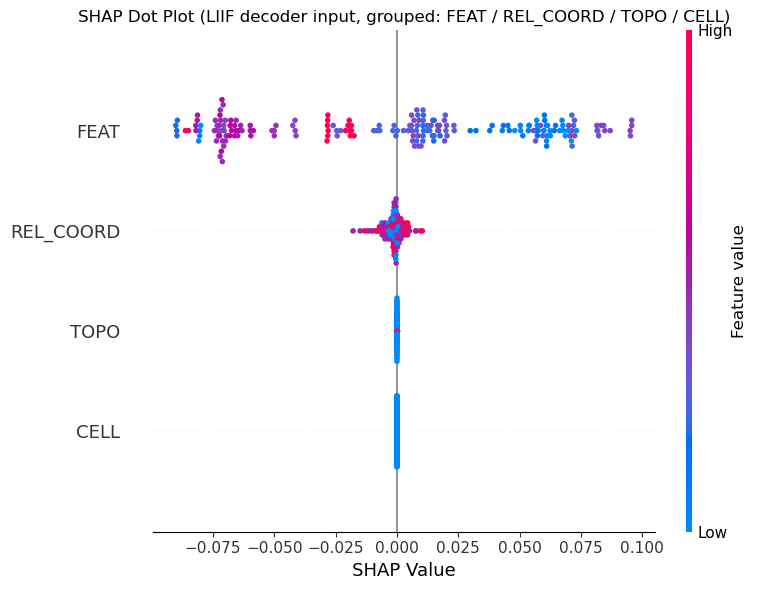

In [5]:
"""
기존 shap_decoder_analysis 코드 뒤에 이어 붙이는 부분입니다.
위쪽(1~9번)은 이전에 작성하신 코드와 동일하다고 가정합니다.

이번 버전은 2309개 차원을 아래 4개 그룹으로 묶어서 보여줍니다.
    FEAT      <- q_feat     (0 ~ 2303, 인코더 latent feature)
    REL_COORD <- rel_coord  (2304 ~ 2305, 상대 좌표 x/y)
    TOPO      <- q_level    (2306, 지형/고도 정보)
    CELL      <- rel_cell   (2307 ~ 2308, 셀 크기 x/y)

그룹 내부 여러 차원을 합칠 때는 mean이 아니라 SUM을 사용합니다.
(mean은 차원 수가 다른 그룹끼리 "차원당 평균"을 비교하게 되어
 q_feat처럼 2304차원인 그룹이 상대적으로 작아 보이는 왜곡이 생길 수 있음.
 sum은 "그 그룹이 최종 출력에 실제로 기여한 총량"을 그대로 보여줌.)
"""

import numpy as np
import shap
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 0. shap_arr / test_x 정리 (shape만 정리, 값은 그대로)
# ------------------------------------------------------------
shap_arr_2d = np.asarray(shap_arr)
if shap_arr_2d.ndim == 3:
    assert shap_arr_2d.shape[-1] == 1, f"예상 못한 shape: {shap_arr_2d.shape}"
    shap_arr_2d = shap_arr_2d.squeeze(-1)   # (n_test, 2309)

if hasattr(test_x, "detach"):
    test_x_np = test_x.detach().cpu().numpy()
else:
    test_x_np = np.asarray(test_x)

# ------------------------------------------------------------
# 1. 그룹 정의 (요청하신 이름 그대로: FEAT, REL_COORD, TOPO, CELL)
# ------------------------------------------------------------
GROUPS = {
    "FEAT":      slice(0, 2304),
    "REL_COORD": slice(2304, 2306),
    "TOPO":      slice(2306, 2307),
    "CELL":      slice(2307, 2309),
}
feature_names = list(GROUPS.keys())

# ------------------------------------------------------------
# 2. 그룹별 SUM (mean 아님)
#    - SHAP 값: 그룹 내 차원들을 부호 그대로 합산 (beeswarm에서 +/- 방향이 의미를 가지도록)
#    - feature 값(색상용): 그룹 내 차원들의 합 (동일한 기준으로 맞춤)
# ------------------------------------------------------------
shap_grouped = np.column_stack([
    shap_arr_2d[:, sl].sum(axis=1) for sl in GROUPS.values()
])   # [n_test, 4]

feature_values_grouped = np.column_stack([
    test_x_np[:, sl].sum(axis=1) for sl in GROUPS.values()
])   # [n_test, 4]

# ------------------------------------------------------------
# 3. 참고용 콘솔 출력: 그룹별 |SHAP| 평균 (9번 섹션 스타일, 비교용으로만)
# ------------------------------------------------------------
print("Group SHAP importance (참고용, mean(abs) 기준 — 9번 섹션과 같은 정의)")
for name, sl in GROUPS.items():
    imp = np.mean(np.abs(shap_arr_2d[:, sl]))
    print(f"{name:10s}:", imp)

# ------------------------------------------------------------
# 4. beeswarm(dot) plot 그리기
# ------------------------------------------------------------
plt.figure(figsize=(8, 6))
shap.summary_plot(
    shap_grouped,
    features=feature_values_grouped,
    feature_names=feature_names,
    show=False,
    plot_size=None,
)

plt.title("SHAP Dot Plot (LIIF decoder input, grouped: FEAT / REL_COORD / TOPO / CELL)")
plt.xlabel("SHAP Value")

plt.tight_layout()
plt.savefig("/mnt/user-data/outputs/shap_dot_plot_liif_grouped4.png", dpi=150)
plt.show()

print("저장 완료: /mnt/user-data/outputs/shap_dot_plot_liif_grouped4.png")